In [6]:
from pathlib import Path

data_dir = Path("../data/STR")
files = list(data_dir.glob("*.tif"))
print(f"Total pictures: {len(files)}")

Total pictures: 10446


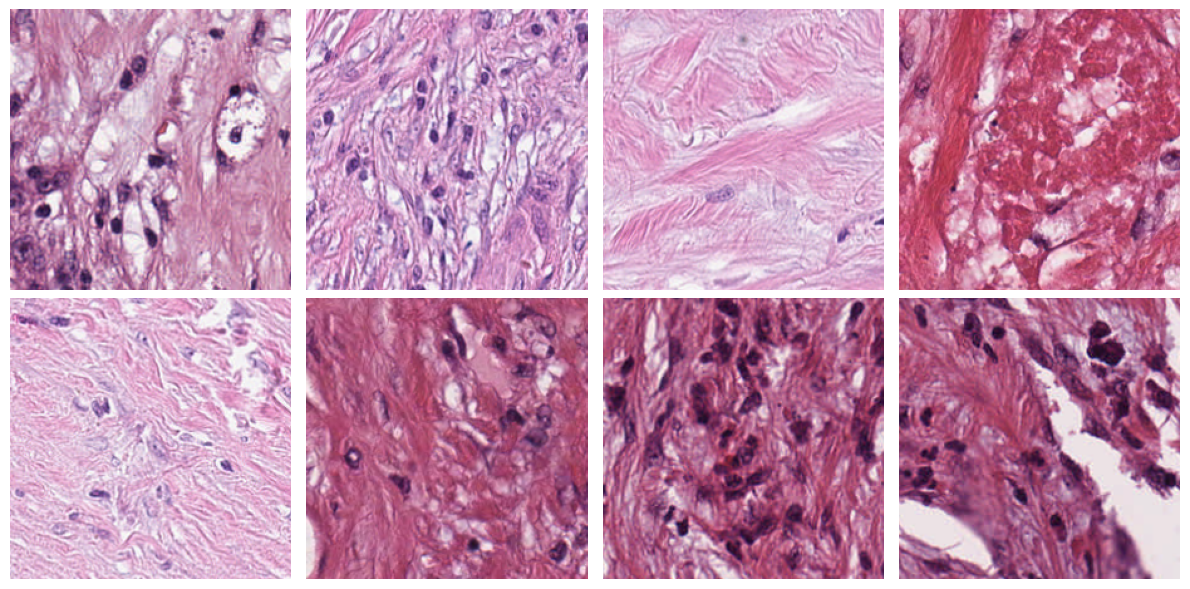

In [7]:
from PIL import Image
import random
import matplotlib.pyplot as plt

sample = random.sample(files,8)

fig, axes = plt.subplots(2, 4, figsize=(12,6))

for ax, img_path in zip(axes.ravel(), sample):
    img = Image.open(img_path)

    ax.imshow(img)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [8]:
img = Image.open(files[0])

print(img.size)

(224, 224)


# Feature Extraction with ResNet50
In this section, a pretrained ResNet50 model is used to extract deep feature representations from stromal tissue images. The final classification layer is removed so that the network outputs feature vectors instead of ImageNet class predictions.

Images are converted to PyTorch tensors and normalized using the ImageNet mean and standard deviation values. This preprocessing matches the conditions used when training the pretrained ResNet50 model.

Std and mean values for image normalization: https://github.com/openai/CLIP/issues/20

In [ ]:
import torch
from torchvision import models
from torchvision import transforms

model = models.resnet50(weights="DEFAULT")
model.fc = torch.nn.Identity() # Remove the final classification layer and output feature vectors
model.eval()
print("Model loaded")

# Define preprocessing steps for ResNet50
transform = transforms.Compose([

    # Convert PIL image to PyTorch tensor
    transforms.ToTensor(),

    # Normalize using ImageNet statistics
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

Model loaded


# Feature Extraction from a Single Image

Before processing the full dataset, feature extraction is tested on a single stromal image to verify that the workflow functions correctly.

In [12]:
from PIL import Image

# Load one stromal image
img = Image.open(files[0]).convert("RGB")

# Apply preprocessing
x = transform(img)

# Add batch dimension
x = x.unsqueeze(0)

print(x.shape)

torch.Size([1, 3, 224, 224])


In [13]:
# Extract deep features
with torch.no_grad():
    features = model(x)

print(features.shape)

torch.Size([1, 2048])


# Feature Extraction for a Subset of Stromal Images

To validate the workflow before processing the full dataset, features are extracted from a subset of stromal tissue images.

In [ ]:
import numpy as np

# Select a subset of Images
subset_files = files[:500]

feature_list = []

# Extract features from each Image. Batch size is 1 first. 
for img_path in subset_files:

    img = Image.open(img_path).convert("RGB")

    x = transform(img)
    x = x.unsqueeze(0)

    with torch.no_grad():
        features = model(x)

    feature_list.append(
        features.squeeze().numpy()
    )

# Create feature matrix
feature_matrix = np.array(feature_list)

print(feature_matrix.shape)

(500, 2048)


# K-Means Clustering
The extracted feature vectors are clustered using K-Means to identify potential stromal tissue subtypes.

In [ ]:
from sklearn.cluster import KMeans
import pandas as pd

# Cluster images into three groups
kmeans = KMeans(
    n_clusters = 3,
    random_state = 42
)

# Perform K-Means clustering on the extracted feature vectors
labels = kmeans.fit_predict(feature_matrix)
print(labels.shape)

print("Number of images in each cluster:")
pd.Series(labels).value_counts().sort_index()

(500,)
KMeans finds three groups:


0    156
1    151
2    193
Name: count, dtype: int64

#### Initial Clustering Results

K-Means clustering divided the 500 stromal images into three groups containing 156, 151 and 193 images, respectively.

# UMAP Visualization

UMAP is used to project the 2048-dimensional feature vectors into two dimensions, enabling visualization of the clustering structure.

c:\projektit\stroma-clustering\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\projektit\stroma-clustering\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


(500, 2)


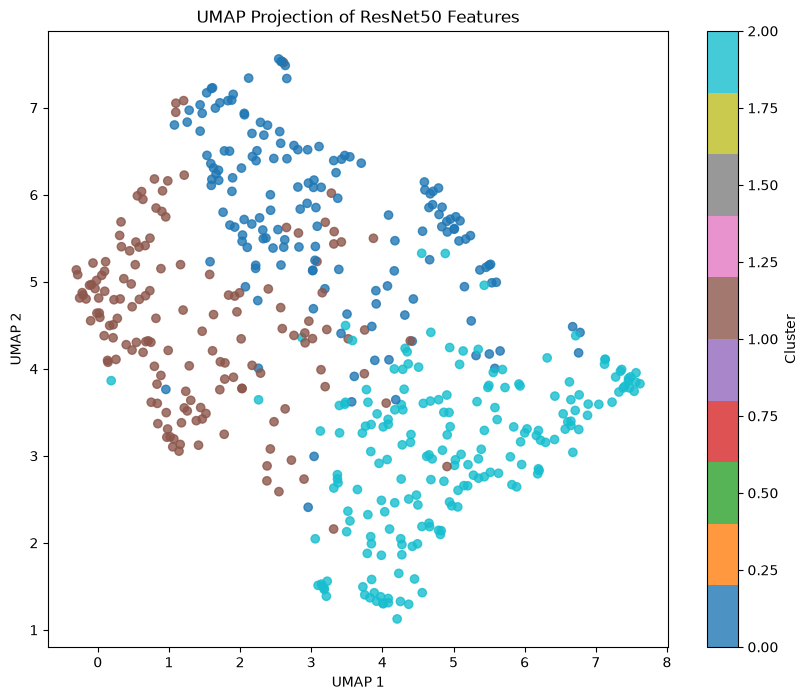

In [24]:
import umap
import matplotlib.pyplot as plt

# Reduce the feature vectors from 2048 dimension to 2 dimensions

embedding = umap.UMAP(random_state = 42).fit_transform(feature_matrix)

print(embedding.shape)

plt.figure(figsize= (10,8))

scatter = plt.scatter(
    embedding[:, 0],
    embedding[:, 1],
    c = labels,
    cmap= "tab10",
    alpha = 0.8
)

plt.colorbar(scatter, label="Cluster")
plt.title("UMAP Projection of ResNet50 Features")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")

plt.show()

# Cluster Inspection

Representative images from each cluster are visualized to investigate whether the clusters correspond to distinct stromal morphologies.

156
151
193


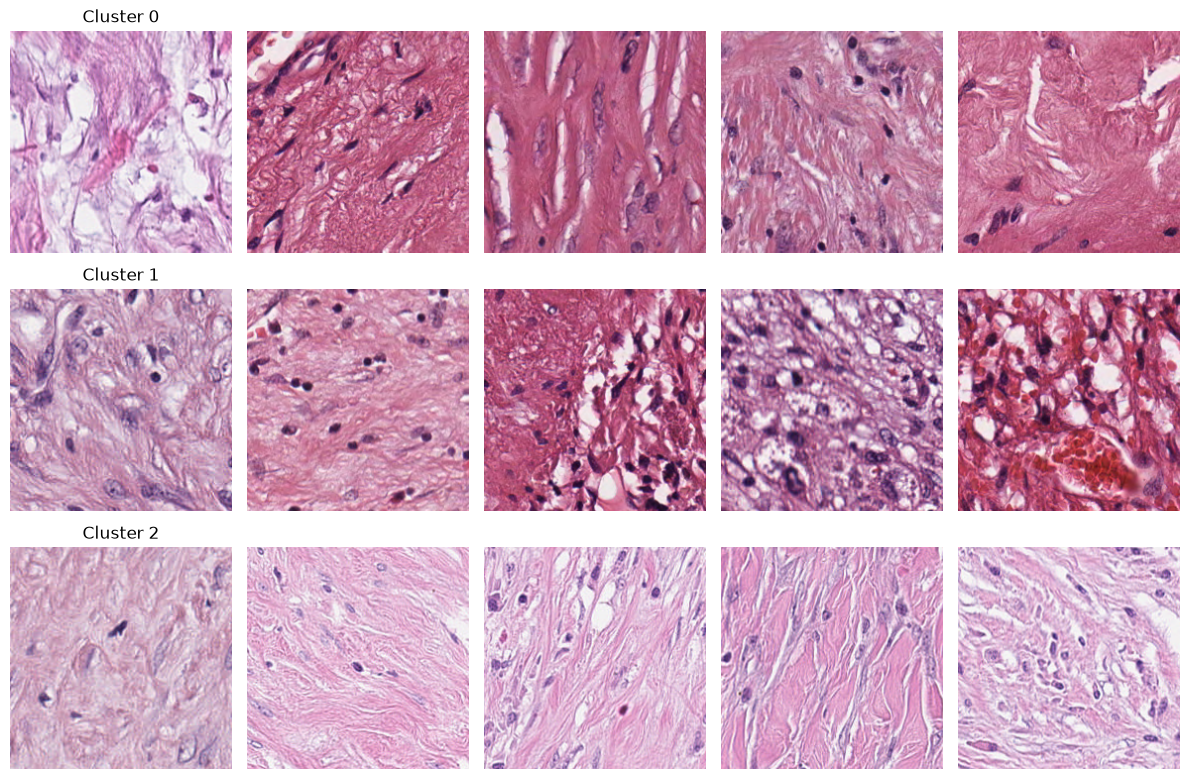

In [29]:
cluster_0 = np.where(labels == 0)[0]
cluster_1 = np.where(labels == 1)[0]
cluster_2 = np.where(labels == 2)[0]

print(len(cluster_0))
print(len(cluster_1))
print(len(cluster_2))

fig, axes = plt.subplots(3, 5, figsize=(12, 8))

clusters = [cluster_0, cluster_1, cluster_2]

for row, cluster in enumerate(clusters):

    sample_idx = np.random.choice(
        cluster,
        5,
        replace=False
    )

    for col, idx in enumerate(sample_idx):

        img = Image.open(subset_files[idx])

        axes[row, col].imshow(img)
        axes[row, col].axis("off")

        if col == 0:
            axes[row, col].set_title(
                f"Cluster {row}"
            )

plt.tight_layout()
plt.show()

# Cluster Inspection
Random examples from each cluster are visualized to assess whether the identified clusters correspond to distinct stromal morphologies.

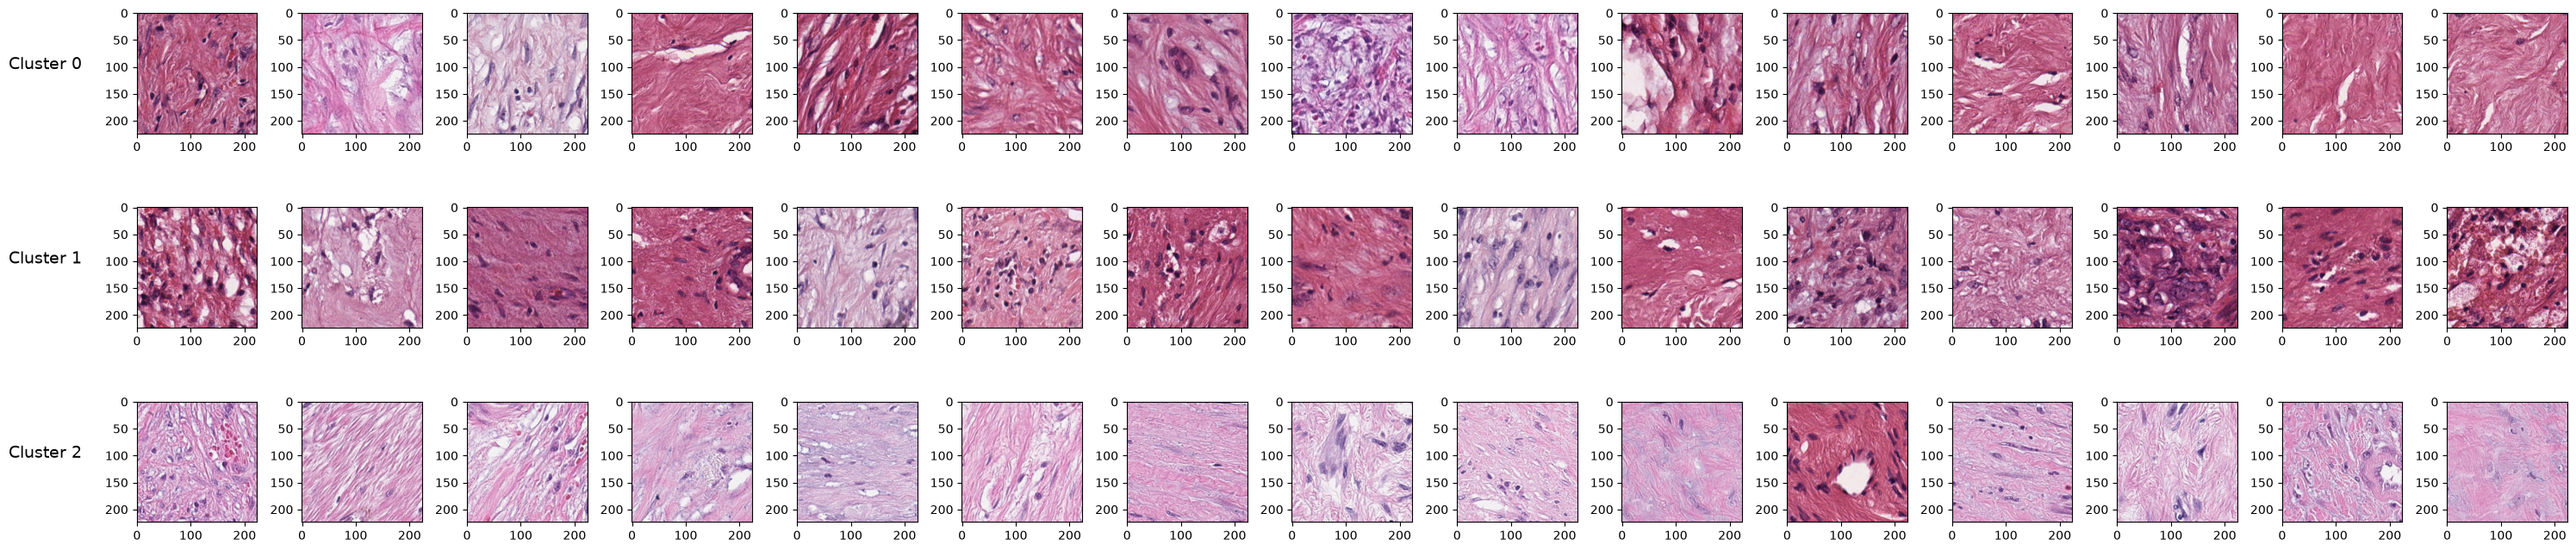

In [32]:
fig, axes = plt.subplots(3, 15, figsize=(30, 7))

clusters = [cluster_0, cluster_1, cluster_2]

cluster_titles = [
    "Cluster 0",
    "Cluster 1",
    "Cluster 2"
]

for row, cluster in enumerate(clusters):

    sample_idx = np.random.choice(
        cluster,
        15,
        replace=False
    )

    for col, idx in enumerate(sample_idx):

        img = Image.open(subset_files[idx])

        axes[row, col].imshow(img)
        axes[row, col].axis("on")

    axes[row, 0].set_ylabel(
        cluster_titles[row],
        fontsize=14,
        rotation=0,
        labelpad=50
    )

plt.tight_layout()
plt.show()